# Explore models of gut-immune models and their optimal solutions
We consider a model for a microbe $G_\mu$ that enters the gut at rate $b_\mu$, grows in the gut by exploiting niche $n_\mu$ and depleting that nich at rate $s_\mu$, subject to pressure from the immune system $X$:
\begin{align}
\dot{G}_\mu = (n_\mu - s_\mu G_\mu - X_\mu)G_\mu + b_\mu,
\end{align}
with immune pressure mediated by inflammatory cells ($\lambda$) and tolerant cells ($w$):
\begin{align}
X_\mu(\lambda,w) = \gamma \frac{\lambda^2}{\lambda + w}.
\end{align}
The steady-state solution for this system can be shown to be:
\begin{align}
\tilde{G_\mu} = \frac{\frac{n_\mu -X_\mu}{s_\mu} + \left[\left(\frac{n_\mu -X_\mu}{s_\mu}\right)^2 + 4\frac{b_\mu}{s_\mu} \right]^{\frac{1}{2}}}{2}.
\end{align}

We assuming that upon establishment the microbe causes harm to the host organism at rate $h_\mu$, and further that the long-term immune response to the microbe is slower than the establishment time of the microbe. We seek the solution to the optimization problem
\begin{align}
\min_{\lambda,w}\left\{ h_\mu G_\mu + \sum_k \beta_k F_k(\lambda, w) \right\},
\end{align}
such that $\lambda, w \geq 0$. The second term corresponds to additional costs from mounting an immune response. In what follows we will take, $F(\lambda, w) = X_\mu(\lambda, w)$.

To solve this problem we define the lagrangian in terms of $X_\mu$
\begin{align}
L(X_\mu, \delta) =  h_\mu G_\mu + \beta X_\mu + \delta(l^2 - X_\mu),
\end{align}
where $l$ is real and $\beta \geq 0$. From the KKT conditions, the optimal solution will satisfy,
\begin{align}
\frac{\partial L}{\partial X} &= -\frac{h}{2s} - \frac{h}{2s}\frac{\frac{n_\mu -X_\mu}{s_\mu}}{\left[\left(\frac{n_\mu -X_\mu}{s_\mu}\right)^2 + 4\frac{b_\mu}{s_\mu} \right]^{\frac{1}{2}}} + \beta - \delta = 0\\
\frac{\partial L}{\partial \delta} &= l^2 - X = 0.
\end{align}
The first equation implies that $\beta - \delta < \frac{h}{s}$ for there to be an optimal point away from the boundary, since otherwise the derivative cannot equal zero for any value of $X$.

We have two cases to consider. In the first case the constraint $X = 0$ is active and $l = 0$ and $\delta$ is not necessarily zero, so we check the value of the lagrangian at the boundary. In the second case, the constraint is inactive and $l^2 > 0$ and $\delta = 0$. This situation can then be solved to find
\begin{align}
\tilde{X} = n_\mu - sgn\left(\beta -\frac{h_\mu}{2s_\mu}\right) s_\mu\left[\frac{\left(\beta -\frac{h_\mu}{2s_\mu}\right)^2 4b_\mu}{\beta\left(\frac{h_\mu}{s_\mu} -\beta\right)}\right]^{\frac{1}{2}},
\end{align}
where the positive branch of the solution is taken when $\beta > \frac{h}{2s}$ and the negative branch is taken when $\beta < \frac{h}{2s}$. So we may write succinctly,
\begin{align}
\tilde{X} = \max\left\{0,n_\mu - s_\mu\frac{2\left(\beta -\frac{h_\mu}{2s_\mu}\right) b_\mu^{\frac{1}{2}}}{\left[\beta\left(\frac{h_\mu}{s_\mu} -\beta\right)\right]^{\frac{1}{2}}}\right\}.
\end{align}
To map back to the original problem, we solve
\begin{align}
\tilde{X} = X(\tilde{\lambda},\tilde{w}),
\end{align}
which will lead to 1-D manifold of possible solutions.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import patheffects
import scipy.optimize
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint
from math import erf
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import mpltern
from mpltern.datasets import get_triangular_grid
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [2]:
# Define parameters
gam = 1 # Immune pressure per inflammatory cell
n = 1 # Niche supply
s = 1/10 # Niche depletion rate per microbe
b = 0.1*s # Immigration rate
h = 1 # Harmfulness of microbe
beta = 0.1*h/s # Cost of immune pressure

In [3]:
# Define functions
def X(l,w): # Immune-pressure
    out = gam*l**2/(l + w)
    return out

def G(l,w): # Microbe steady state population
    out = (n-X(l,w))/(2*s) + np.sqrt((n-X(l,w))**2/s**2 + 4*b/s)/2
    return out

def net_harm(l,w):
    out = h*G(l,w)
    return out

def lagrangian(x, beta = 1.0): # Cost function
    out = net_harm(x[0],x[1]) + beta*X(x[0],x[1])
    return out

## Check analytic solution

In [4]:
# Plot numerical values and analytic values verus beta

## Low cost of immunity: $\beta \leq \frac{h}{s}$
There is a non-zero optimal solution.

In [5]:
# Visualize cost landscape
rng = 15
pnts = 100
lvec = np.linspace(0.01, rng, pnts)
wvec = np.linspace(0.01, rng, pnts)

l, w = np.meshgrid(lvec, wvec)
z = net_harm(l,w) + beta*X(l,w)


fig = go.Figure(data=[go.Surface(z=z, x=l, y=w)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='[Lagrangian] = h*G(l,w) + beta*X', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Inflammation, $\lambda$',
    yaxis_title=r'Tolerance, $w$',
    zaxis_title=r'$L(\lambda,w)$'
))

fig.show()

In [19]:
# Numerically optimize 
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
res_good_beta = minimize(lagrangian, args = (beta),
         x0 = np.array([rng/2,rng/2]),
         tol=1e-6,
         constraints = [constr1, constr2])

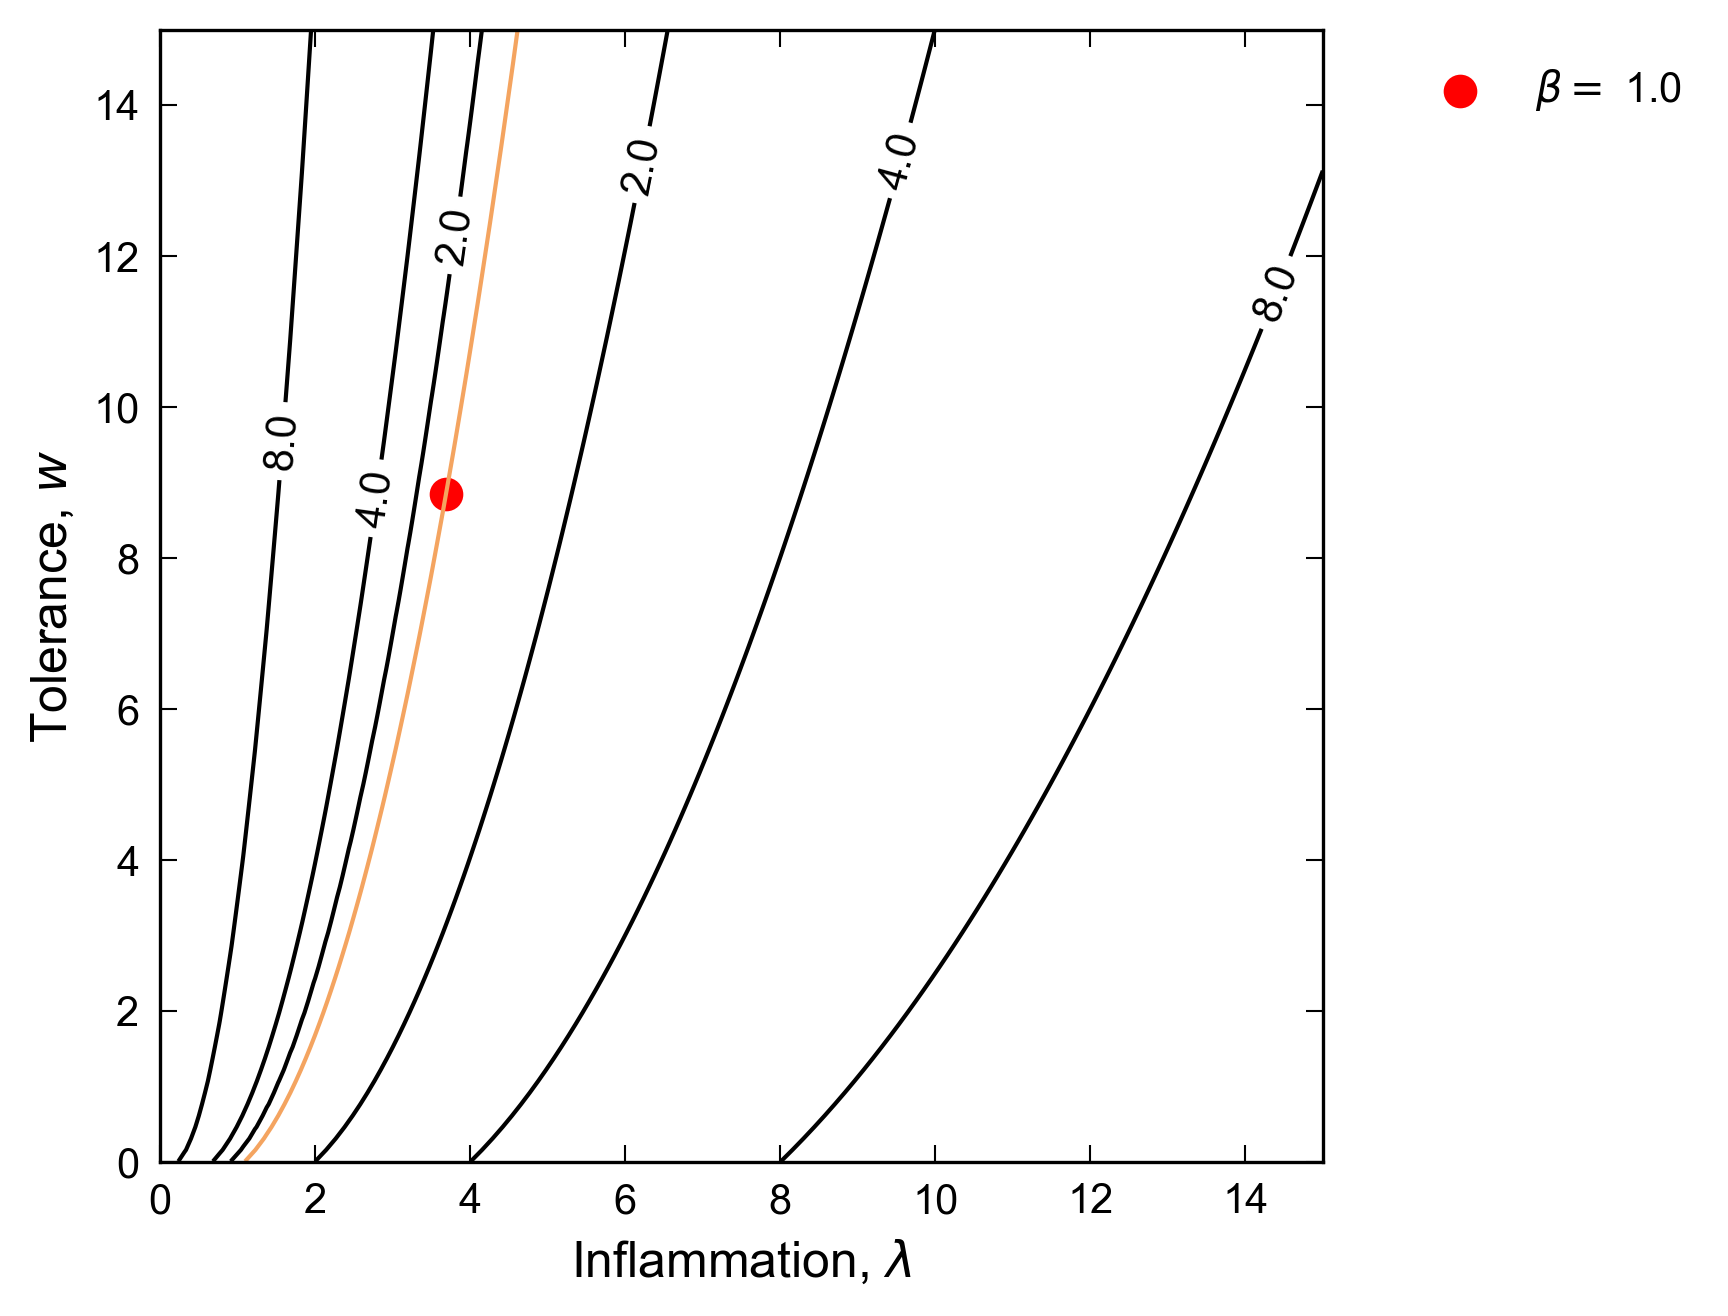

In [20]:
# Identify manifold of optimal solutions
fig, ax = plt.subplots(dpi = 150, figsize=(5, 5))

# Evaluate some stuff to plot
obj = net_harm(l,w) + beta*X(l,w)
g1 = X(l,w) - X(res_good_beta.x[0], res_good_beta.x[1])

cntr = ax.contour(l, w, obj, [0.01, 0.1, 0.5, 1, 2, 4, 8, 16],
                  colors='black')
ax.clabel(cntr, fmt="%2.1f", use_clabeltext=True)
ax.scatter(res_good_beta.x[0],res_good_beta.x[1], color = 'red', s = 50, label = r"$\beta=$ "+str(beta))

cg1 = ax.contour(l, w, g1, [0], colors='sandybrown')
#cg1.set(path_effects=[patheffects.withTickedStroke(angle=135)])

ax.set(ylabel=r'Tolerance, $w$',xlabel=r'Inflammation, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

ax.set_xlim(0, rng)
ax.set_ylim(0, rng)

plt.show()

## High cost of immunity: $\beta = \frac{h}{s}$
Optimal solution if located at the origin.

In [8]:
# Visualize cost landscape
rng = 15
pnts = 100
lvec = np.linspace(0.01, rng, pnts)
wvec = np.linspace(0.01, rng, pnts)

l, w = np.meshgrid(lvec, wvec)
z = net_harm(l,w) + (h/s)*X(l,w)


fig = go.Figure(data=[go.Surface(z=z, x=l, y=w)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='[Lagrangian] = h*G(l,w) + beta*X', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Inflammation',
    yaxis_title=r'Tolerance',
    zaxis_title=r'L(\lambda,w)'
))

fig.show()

In [21]:
# Numerically optimize
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
res_bad_beta = minimize(lagrangian, args = (h/s),
         x0 = np.array([rng/2,rng/2]),
         tol=1e-6,
         constraints = [constr1, constr2])

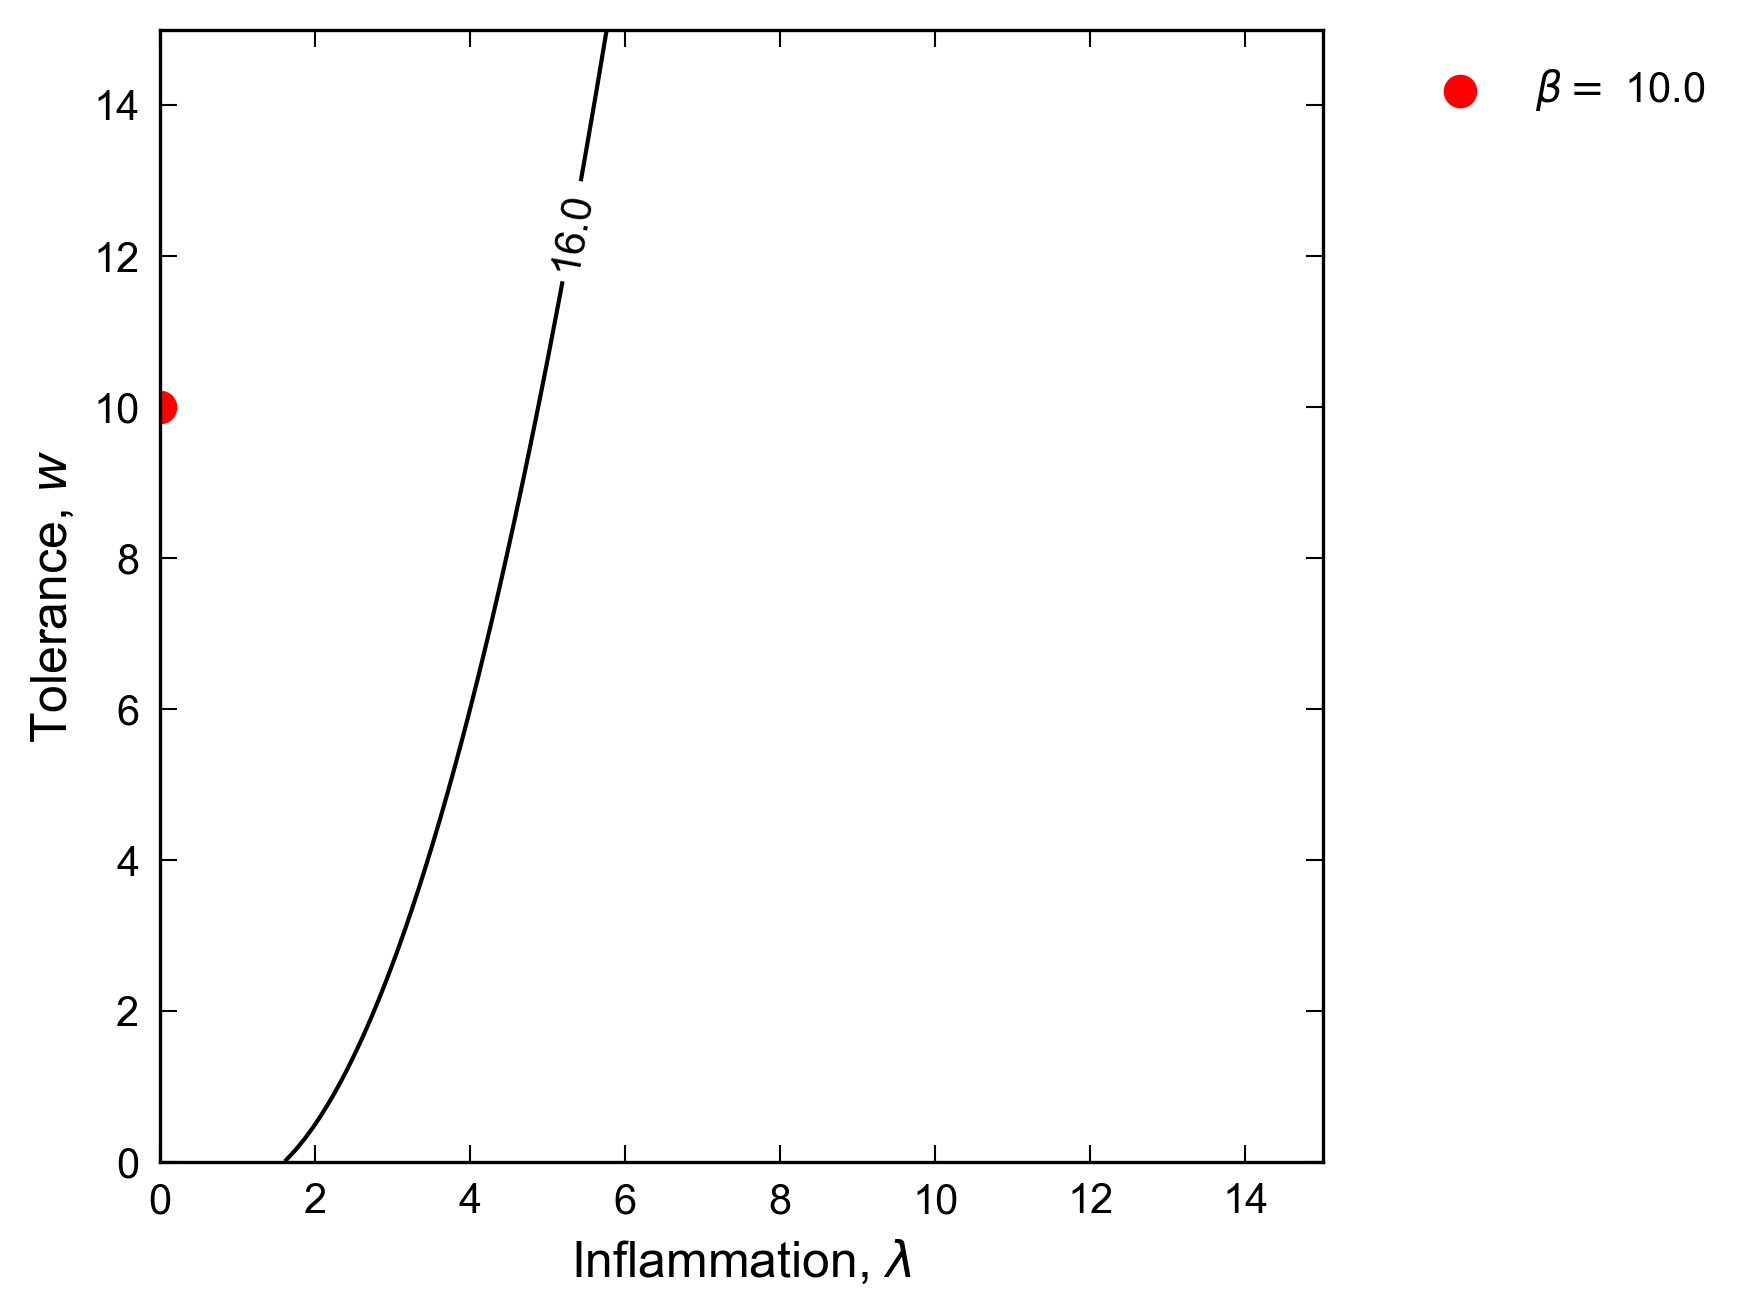

In [22]:
fig, ax = plt.subplots(dpi = 150, figsize=(5, 5))

# Evaluate some stuff to plot
obj = net_harm(l,w) + h/s*X(l,w)
g1 = X(l,w) - X(res_bad_beta.x[0], res_bad_beta.x[1])

cntr = ax.contour(l, w, obj, [0.01, 0.1, 0.5, 1, 2, 4, 8, 16],
                  colors='black')
ax.clabel(cntr, fmt="%2.1f", use_clabeltext=True)
ax.scatter(res_bad_beta.x[0],res_bad_beta.x[1], color = 'red', s = 50, label = r"$\beta=$ "+str(h/s))

cg1 = ax.contour(l, w, g1, [0], colors='sandybrown')
#cg1.set(path_effects=[patheffects.withTickedStroke(angle=135)])

ax.set(ylabel=r'Tolerance, $w$',xlabel=r'Inflammation, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

ax.set_xlim(0, rng)
ax.set_ylim(0, rng)

plt.show()

## Trying a different immune cost function: $F(\lambda, w) = \lambda$
We will observe that doing this "regularizes" the solution, but leads to tolerance being ignored.

In [11]:
def mod_lagrangian(x, beta = 1.0): # Cost function
    out = net_harm(x[0],x[1]) + beta*x[0]
    return out

In [12]:
# Visualize cost landscape
rng = 15
pnts = 100
lvec = np.linspace(0.01, rng, pnts)
wvec = np.linspace(0.01, rng, pnts)

l, w = np.meshgrid(lvec, wvec)
z = net_harm(l,w) + beta*l


fig = go.Figure(data=[go.Surface(z=z, x=l, y=w)])
fig.update_traces(contours_z=dict(show=True, usecolormap=True,
                                  highlightcolor="limegreen", project_z=True))
fig.update_layout(title='[Lagrangian] = h*G(l,w) + beta*X', autosize=False,
                  scene_camera_eye=dict(x=1.87, y=0.88, z=-0.64),
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

# Update the layout
fig.update_layout(scene=dict(
    xaxis_title=r'Inflammation',
    yaxis_title=r'Tolerance',
    zaxis_title=r'L(\lambda,w)'
))

fig.show()

In [13]:
# Numerically optimize
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
res_mod_lag = minimize(mod_lagrangian, args = (beta),
         x0 = np.array([rng,rng]),
         tol=1e-6,
         constraints = [constr1, constr2])

In [14]:
res_mod_lag

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: 1.1897368447029915
       x: [ 1.084e+00  1.905e-12]
     nit: 22
     jac: [ 2.512e-03  9.975e-01]
    nfev: 77
    njev: 22

In [23]:
res_mod_lag.nfev

77

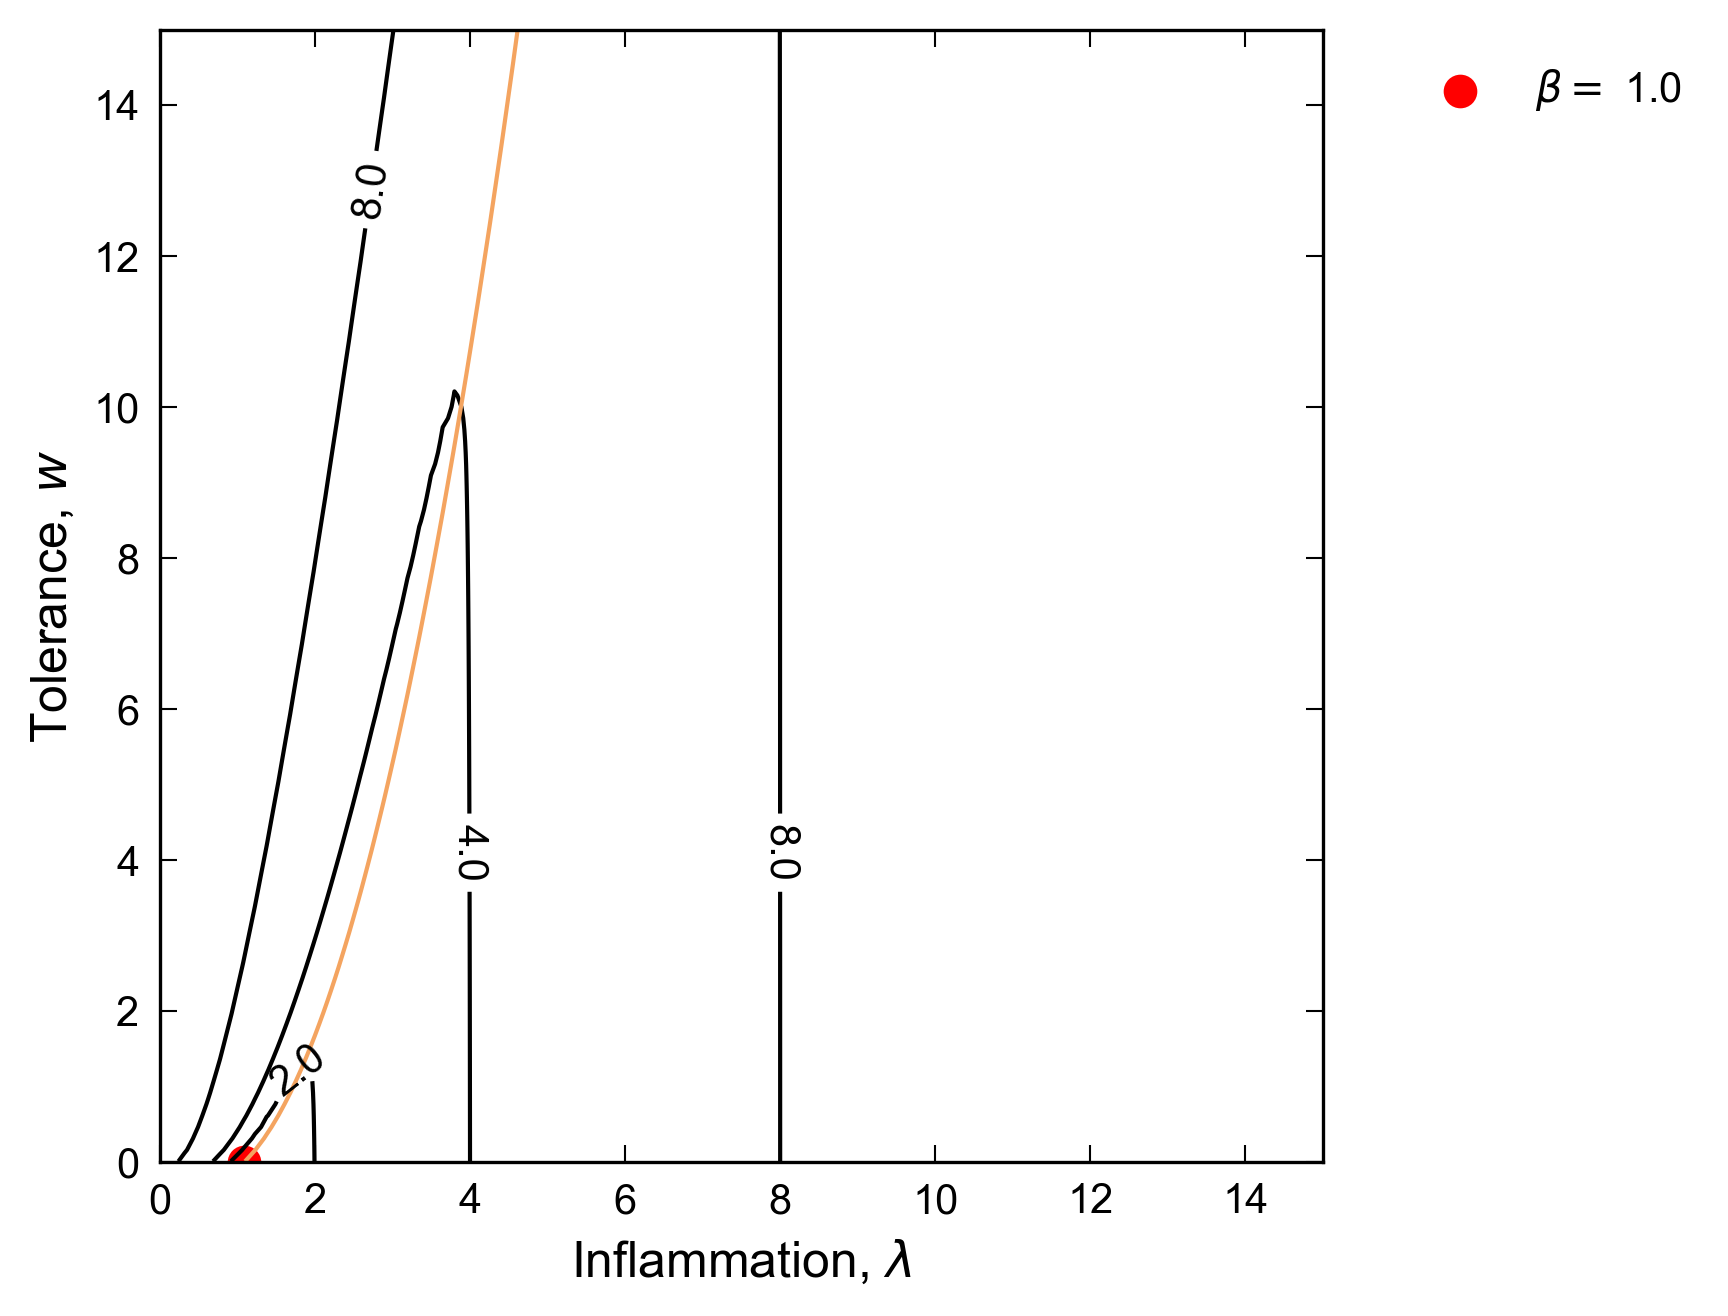

In [15]:
fig, ax = plt.subplots(dpi = 150, figsize=(5, 5))

# Evaluate some stuff to plot
obj = net_harm(l,w) + beta*l
g1 = X(l,w) - X(res_mod_lag.x[0], res_mod_lag.x[1])

cntr = ax.contour(l, w, obj, [0.01, 0.1, 0.5, 1, 2, 4, 8, 16],
                  colors='black')
ax.clabel(cntr, fmt="%2.1f", use_clabeltext=True)
ax.scatter(res_mod_lag.x[0],res_mod_lag.x[1], color = 'red', s = 50, label = r"$\beta=$ "+str(beta))

cg1 = ax.contour(l, w, g1, [0], colors='sandybrown') # Optimal contour from original problem"
#cg1.set(path_effects=[patheffects.withTickedStroke(angle=135)])

ax.set(ylabel=r'Tolerance, $w$',xlabel=r'Inflammation, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

ax.set_xlim(0, rng)
ax.set_ylim(0, rng)

plt.show()

## Can we add a term that depends on $w$ to encourage the immune system to use tolerance?
Such a term probably needs to be a negative cost or benefit. We could also introduce constraints on the magnitude of the inflammatory immune response. In particular a lower bound or equality constraint as was previously proposed. "The inflammatory immune system just can't help itself."

In [16]:
# Numerically optimize
constr1 = LinearConstraint([1.0,0.0], 0.0)
constr2 = LinearConstraint([0.0,1.0], 0.0)
def constraint3(x):
    return x[0] - 20*G(x[0],x[1])
constr3 = NonlinearConstraint(constraint3, 0, 0)

# define constraints
res_contr_lag = minimize(lagrangian, args = (beta),
         x0 = np.array([rng,rng]),
         tol=1e-6,
         constraints = [constr1, constr2, constr3])

In [17]:
res_contr_lag

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: 1.1897366596103223
       x: [ 2.108e+00  1.991e+00]
     nit: 59
     jac: [ 1.181e-04 -4.086e-05]
    nfev: 220
    njev: 59

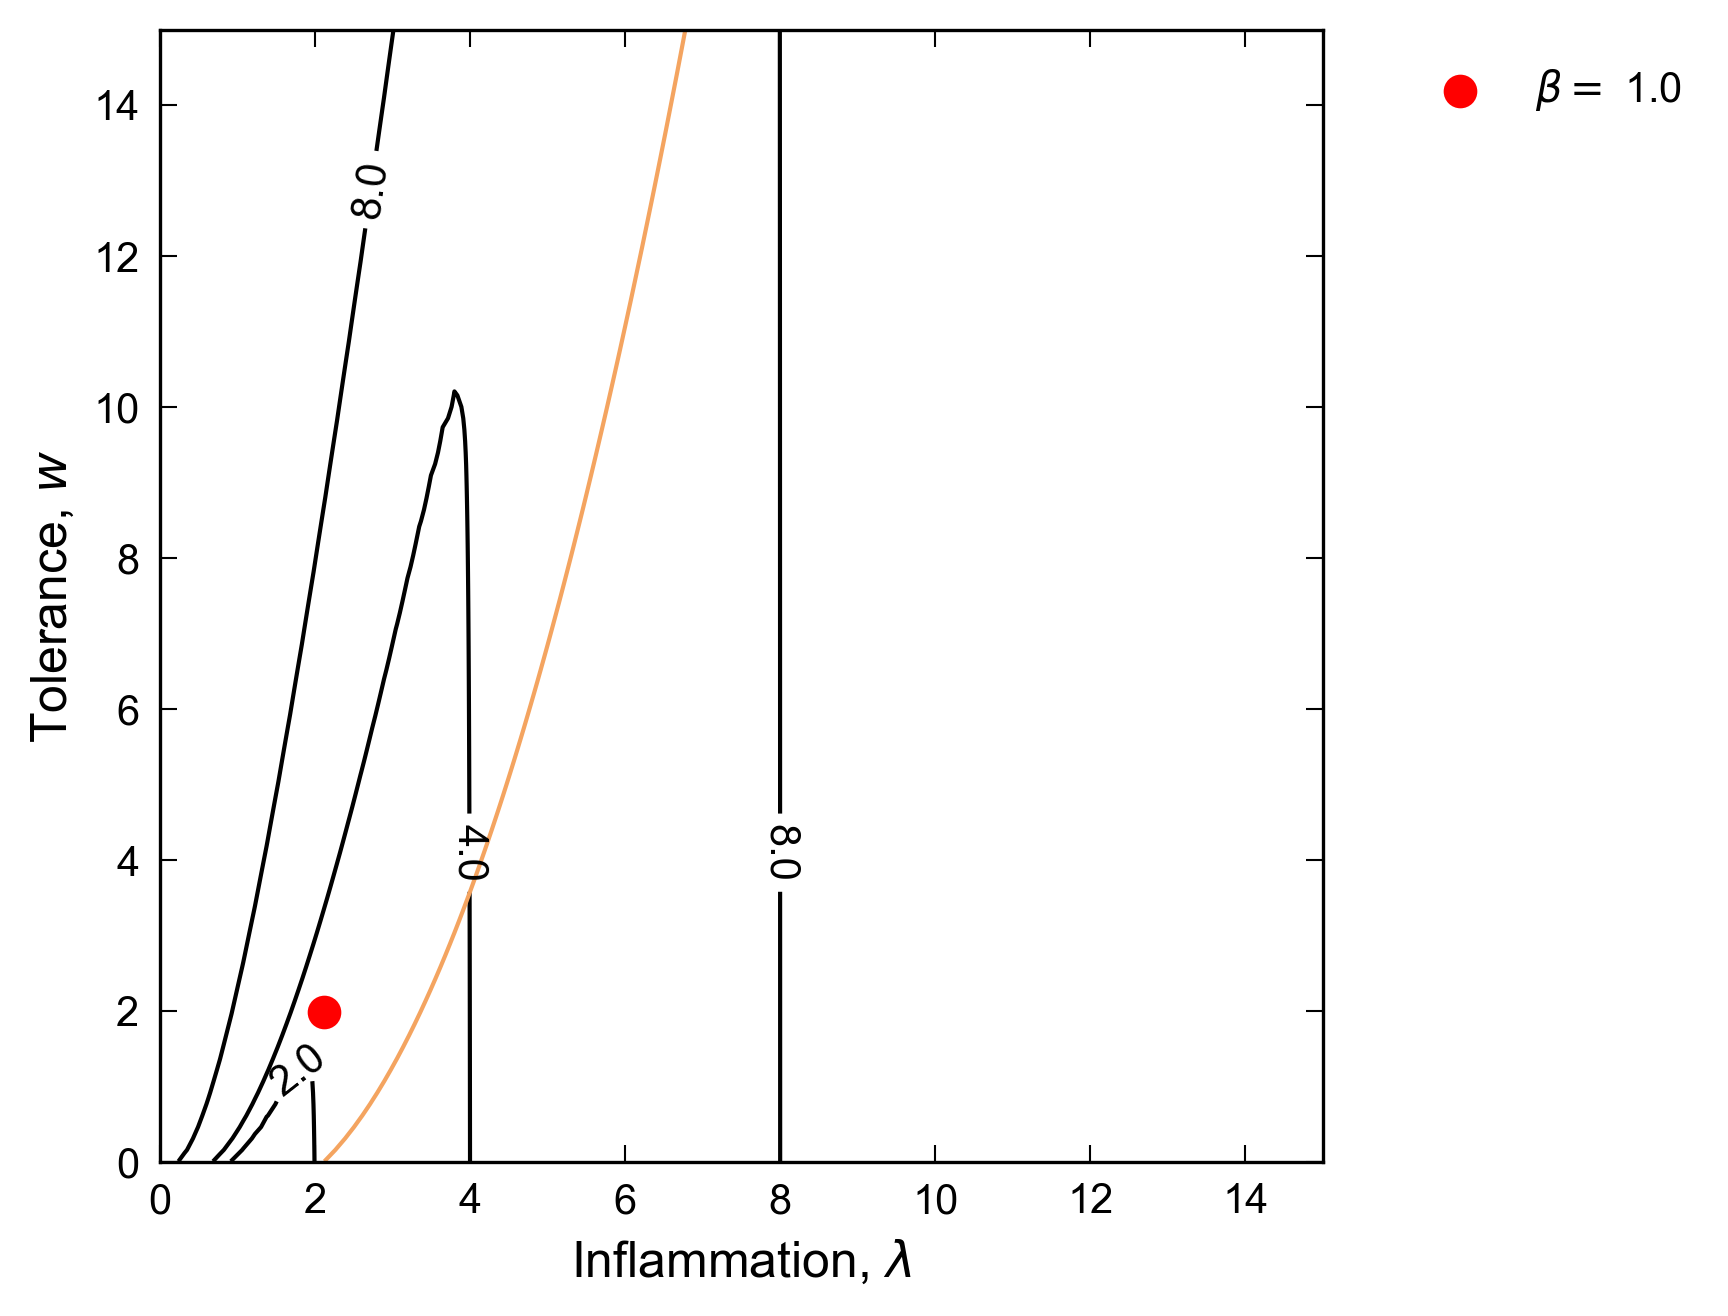

In [18]:
fig, ax = plt.subplots(dpi = 150, figsize=(5, 5))

# Evaluate some stuff to plot
obj = net_harm(l,w) + beta*l
g1 = X(l,w) - X(res_contr_lag.x[0], res_mod_lag.x[1])

cntr = ax.contour(l, w, obj, [0.01, 0.1, 0.5, 1, 2, 4, 8, 16],
                  colors='black')
ax.clabel(cntr, fmt="%2.1f", use_clabeltext=True)
ax.scatter(res_contr_lag.x[0],res_contr_lag.x[1], color = 'red', s = 50, label = r"$\beta=$ "+str(beta))

cg1 = ax.contour(l, w, g1, [0], colors='sandybrown') # Optimal contour from original problem"
#cg1.set(path_effects=[patheffects.withTickedStroke(angle=135)])

ax.set(ylabel=r'Tolerance, $w$',xlabel=r'Inflammation, $\lambda$')
ax.minorticks_off()
ax.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')

ax.set_xlim(0, rng)
ax.set_ylim(0, rng)

plt.show()